In [1]:
%pip install openpyxl
%pip install plotly

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [9]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
df = pd.read_excel("GuttmacherInstituteAbortionDataByState.xlsx", sheet_name="Guttmacher")
df.head()

,U.S. State,"% change in abortion rate, 2017-2020","% change in the no. of abortion clinics, 2017-2020","% change in the no. of abortion providers, 2014-2017","% of all U.S. abortions, by state of occurrence, 2020","% of counties without a known abortion provider, 2014","% of counties without a known clinic, 2020","% of residents obtaining abortions who traveled out of state for care, 2020","% of women aged 15-44 living in a county without a clinic, 2020","% of women aged 15-44 living in a county without an abortion provider, 2014",...,"No. of abortions per 1,000 women aged 15–44, by state of occurrence, 2020","No. of abortions per 1,000 women aged 15–44, by state of residence, 2020","No. of abortions, by state of occurrence, 2020","No. of abortions, by state of residence, 2020","No. of federally funded abortions, 2010","No. of state funded abortions, 2010","Reported public expenditures for abortions (in 000s of dollars), federal, 2015","Reported public expenditures for abortions (in 000s of dollars), state, 2015","Total no. of publicly funded abortions , 2010","Total reported public expenditures for abortions (in 000s of dollars), 2015"
0,Alabama,-6,0,-22,0.6,91,93,47,59,58,...,6.0,9.5,5700,9060,9,0,22,0,9,22
1,Alaska,0,0,-25,0.1,79,87,7,33,17,...,8.6,9.2,1240,1320,0,835,0,216,835,216
2,Arizona,1,0,-8,1.4,80,80,6,18,19,...,9.3,9.7,13320,13820,1,13,28,11,14,40
3,Arkansas,2,-33,0,0.3,97,99,37,86,77,...,5.6,7.8,3250,4510,0,0,0,0,0,0
4,California,17,7,-18,16.6,24,38,0,3,1,...,19.2,19.0,154060,152400,0,88466,0,32613,88466,32613


In [3]:
# VISUALIZATION 1
FILE = "GuttmacherInstituteAbortionDataByState.xlsx"
COL = "% of women aged 15-44 living in a county without a clinic, 2020"

df = pd.read_excel(FILE, sheet_name="Guttmacher").rename(columns={"U.S. State": "state"})
df[COL] = pd.to_numeric(df[COL])

ABBR = {"Alabama":"AL","Alaska":"AK","Arizona":"AZ","Arkansas":"AR","California":"CA","Colorado":"CO",
"Connecticut":"CT","Delaware":"DE","District of Columbia":"DC","Florida":"FL","Georgia":"GA","Hawaii":"HI",
"Idaho":"ID","Illinois":"IL","Indiana":"IN","Iowa":"IA","Kansas":"KS","Kentucky":"KY","Louisiana":"LA",
"Maine":"ME","Maryland":"MD","Massachusetts":"MA","Michigan":"MI","Minnesota":"MN","Mississippi":"MS",
"Missouri":"MO","Montana":"MT","Nebraska":"NE","Nevada":"NV","New Hampshire":"NH","New Jersey":"NJ",
"New Mexico":"NM","New York":"NY","North Carolina":"NC","North Dakota":"ND","Ohio":"OH","Oklahoma":"OK",
"Oregon":"OR","Pennsylvania":"PA","Rhode Island":"RI","South Carolina":"SC","South Dakota":"SD",
"Tennessee":"TN","Texas":"TX","Utah":"UT","Vermont":"VT","Virginia":"VA","Washington":"WA",
"West Virginia":"WV","Wisconsin":"WI","Wyoming":"WY"}
df["abbr"] = df["state"].map(ABBR)

labels = ["Under 10%", "10-33%", "33-50%", "50-75%", "75%+"]
df["bin"] = pd.cut(df[COL], bins=[-1, 10, 33, 50, 75, 100], labels=labels)
color_map = dict(zip(labels, ["#fde0d2", "#fcae91", "#fb6a4a", "#cb181d", "#67000d"]))

n_majority = int((df[COL] > 50).sum())

fig = px.choropleth(
    df, locations="abbr", locationmode="USA-states", scope="usa",
    color="bin", color_discrete_map=color_map, category_orders={"bin": labels},
    hover_name="state", hover_data={COL: True, "abbr": False, "bin": False},
)
fig.update_traces(marker_line_color="white", marker_line_width=1)
fig.update_layout(
    title=dict(text=f"<b>In {n_majority} States, Most Women Live in a County With No Abortion Clinic</b>"
                    "<br><sup>Share of women aged 15-44 living in a county without a clinic, 2020</sup>",
               x=0.02, xanchor="left"),
    legend=dict(title="Women without a clinic<br>in their county", orientation="h", y=-0.05, x=0.5, xanchor="center"),
    margin=dict(l=20, r=20, t=90, b=60),
    width=1100, height=700,
)

# ---- Labels -------------------------------------------------------------
# Small states get a callout; everything else keeps its label on the state.
# state: (state_lon, state_lat, label_lon, label_lat)
CALLOUTS = {
    "VT": (-72.7, 44.0, -74.5, 47.0),   # up in the empty space over Canada
    "NH": (-71.6, 43.7, -68.5, 43.2),
    "MA": (-71.8, 42.3, -68.5, 41.6),
    "RI": (-71.5, 41.7, -68.5, 40.0),
    "CT": (-72.7, 41.6, -68.5, 38.4),
    "NJ": (-74.5, 40.1, -68.5, 36.8),
    "DE": (-75.5, 39.0, -68.5, 35.2),
    "MD": (-76.8, 39.0, -68.5, 33.6),
    "DC": (-77.0, 38.9, -68.5, 32.0),
}

df["txt"] = df["abbr"] + "<br>" + df[COL].round().astype(int).astype(str) + "%"
df["txtcolor"] = ["white" if v >= 50 else "#222222" for v in df[COL]]

# 1) Normal in-state labels (skip the callout states)
main = df[~df["abbr"].isin(CALLOUTS)]
fig.add_scattergeo(
    locations=main["abbr"], locationmode="USA-states", text=main["txt"], mode="text",
    textfont=dict(size=10, color=main["txtcolor"].tolist()),
    hoverinfo="skip", showlegend=False,
)

# 2) Callouts: leader line + dot on the state + label off to the side
for abbr, (slon, slat, llon, llat) in CALLOUTS.items():
    row = df[df["abbr"] == abbr]
    if row.empty:
        continue
    txt = row["txt"].iloc[0]

    # leader line
    fig.add_scattergeo(
        lon=[slon, llon], lat=[slat, llat], mode="lines",
        line=dict(color="#444444", width=0.8),
        hoverinfo="skip", showlegend=False,
    )
    # dot marking the state end of the line
    fig.add_scattergeo(
        lon=[slon], lat=[slat], mode="markers",
        marker=dict(size=4, color="#222222"),
        hoverinfo="skip", showlegend=False,
    )
    # label (single line so it stays compact in the column)
    fig.add_scattergeo(
        lon=[llon], lat=[llat], mode="text",
        text=[txt.replace("<br>", " ")], textposition="middle right",
        textfont=dict(size=10, color="#222222"),
        hoverinfo="skip", showlegend=False,
    )
fig.update_layout(
    title=dict(
        text=(
            "<b>Percentage of Women Aged 15-44 Without an Abortion Clinic in Their County</b>"
            "<br><sup>In " + str(n_majority) + " states, more than half of women live in a county with no clinic (2020)</sup>"
        ),
        x=0.02, xanchor="left",
        font=dict(size=20),
    ),
    margin=dict(l=20, r=20, t=100, b=60),   # a little extra top room for the title
)

fig.show()

In [4]:
# VISUALIZATION 2 

FILE = "GuttmacherInstituteAbortionDataByState.xlsx"
CLINICS  = "No. of abortion clinics, 2020"
TRAVELED = "% of residents obtaining abortions who traveled out of state for care, 2020"

df = pd.read_excel(FILE, sheet_name="Guttmacher").rename(columns={"U.S. State": "state"})
df[CLINICS] = pd.to_numeric(df[CLINICS], errors="coerce")
df[TRAVELED] = pd.to_numeric(df[TRAVELED], errors="coerce")
df = df.dropna(subset=[CLINICS, TRAVELED])
df = df[df[CLINICS] > 0].copy()

# Trend line: fit y against log10(x) so it plots as a straight line on the log axis
slope, intercept = np.polyfit(np.log10(df[CLINICS]), df[TRAVELED], 1)
x_line = np.logspace(np.log10(df[CLINICS].min()), np.log10(df[CLINICS].max()), 100)
y_line = slope * np.log10(x_line) + intercept

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=df[CLINICS], y=df[TRAVELED], mode="markers",
    marker=dict(size=10, color="#cb181d", opacity=0.7, line=dict(color="white", width=1)),
    text=df["state"],
    hovertemplate="<b>%{text}</b><br>Clinics: %{x}<br>Traveled out of state: %{y}%<extra></extra>",
    showlegend=False,
))
fig.add_trace(go.Scatter(
    x=x_line, y=y_line, mode="lines",
    line=dict(color="#444444", width=2, dash="dash"),
    hoverinfo="skip", showlegend=False,
))

# Label only these three states
LABEL_STATES = {
    "Missouri":     dict(ax=60,  ay=-5),
    "Wyoming":      dict(ax=70,  ay=-25),
    "South Dakota": dict(ax=-70, ay=-5),
}
for st, off in LABEL_STATES.items():
    row = df[df["state"] == st]
    if row.empty:
        continue
    x, y = row[CLINICS].iloc[0], row[TRAVELED].iloc[0]
    fig.add_annotation(
        x=np.log10(x), y=y, xref="x", yref="y",   # log axes take log10 values for annotations
        text=f"<b>{st}</b><br>{int(x)} clinic{'s' if x != 1 else ''}, {y:.0f}% traveled",
        showarrow=True, arrowhead=2, arrowwidth=1, arrowcolor="#444444",
        ax=off["ax"], ay=off["ay"], font=dict(size=11, color="#222222"),
        bgcolor="rgba(255,255,255,0.85)",
    )

fig.update_layout(
    title=dict(
        text="<b>Fewer Clinics, More Travel Out of State</b>"
             "<br><sup>Each dot is a state, 2020</sup>",
        x=0.02, xanchor="left",
    ),
    xaxis=dict(title="Number of abortion clinics (log scale)", type="log",
               showgrid=True, gridcolor="#eeeeee",
               tickvals=[1, 2, 5, 10, 20, 50, 100, 200],
               ticktext=["1", "2", "5", "10", "20", "50", "100", "200"]),
    yaxis=dict(title="% of residents obtaining abortions who traveled out of state",
               range=[-3, 105], ticksuffix="%", showgrid=True, gridcolor="#eeeeee"),
    plot_bgcolor="white",
    margin=dict(l=70, r=30, t=100, b=90),
    width=1000, height=650,
)
fig.show()

In [5]:
# VISUALIZATION 3

FILE = "GuttmacherInstituteAbortionDataByState.xlsx"
CLINICS  = "No. of abortion clinics, 2020"
NOCLINIC = "% of women aged 15-44 living in a county without a clinic, 2020"

df = pd.read_excel(FILE, sheet_name="Guttmacher").rename(columns={"U.S. State": "state"})
df[CLINICS] = pd.to_numeric(df[CLINICS], errors="coerce")
df[NOCLINIC] = pd.to_numeric(df[NOCLINIC], errors="coerce")

d = df[df[CLINICS] == 4].sort_values(NOCLINIC).copy()

# Alternate labels above/below the line so close points (NH 30, AK 33) don't collide
d["pos"] = ["top center" if i % 2 == 0 else "bottom center" for i in range(len(d))]

fig = go.Figure()

# Baseline
fig.add_trace(go.Scatter(
    x=[0, 100], y=[0, 0], mode="lines",
    line=dict(color="#cccccc", width=2), hoverinfo="skip", showlegend=False,
))

# One dot per state, colored on the same red scale as your map
fig.add_trace(go.Scatter(
    x=d[NOCLINIC], y=[0] * len(d), mode="markers+text",
    text=[f"<b>{s}</b><br>{v:.0f}%" for s, v in zip(d["state"], d[NOCLINIC])],
    textposition=d["pos"],
    textfont=dict(size=12, color="#222222"),
    marker=dict(size=18, color=d[NOCLINIC], colorscale=["#fde0d2", "#fb6a4a", "#67000d"],
                cmin=0, cmax=100, line=dict(color="white", width=1.5)),
    hovertemplate="<b>%{customdata}</b><br>%{x} without a clinic in their county<extra></extra>",
    customdata=d["state"], showlegend=False,
))

fig.update_layout(
    title=dict(
    text="<b>Clinic Counts Don't Tell the Whole Story: 5 States With 4 Clinics Each</b>"
         "<br><sup>Yet the share of women living in a county with no clinic ranges from 5% to 68%</sup>",
    x=0.02, xanchor="left",
),
    xaxis=dict(title="% of women aged 15-44 living in a county with no abortion clinic, 2020",
           range=[-5, 105], ticksuffix="%", showgrid=True, gridcolor="#eeeeee", zeroline=False),
    yaxis=dict(visible=False, range=[-1, 1]),
    plot_bgcolor="white",
    margin=dict(l=40, r=40, t=100, b=100),
    width=1000, height=420,
)

fig.show()

In [6]:
# VISUALIZATION 4

FILE = "GuttmacherInstituteAbortionDataByState.xlsx"
CLINICS = "No. of abortion clinics, 2020"
N_ABORT = "No. of abortions, by state of residence, 2020"
RATE    = "No. of abortions per 1,000 women aged 15–44, by state of residence, 2020"

df = pd.read_excel(FILE, sheet_name="Guttmacher").rename(columns={"U.S. State": "state"})
for c in (CLINICS, N_ABORT, RATE):
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = df.dropna(subset=[CLINICS, N_ABORT, RATE]).copy()

# The sheet has no population column, so back it out: abortions / (abortions per 1,000) = women 15-44
df["women"] = df[N_ABORT] / df[RATE] * 1000
df["cpk"] = df[CLINICS] / df["women"] * 100_000

HIGHLIGHT = {
    "Rhode Island": dict(ax=70, ay=0,  note="low clinics, high use"),
    "Missouri":     dict(ax=60, ay=80, note="1 clinic, typical use"),
}
hl = df[df["state"].isin(HIGHLIGHT)]
rest = df[~df["state"].isin(HIGHLIGHT)]

fig = go.Figure()

# All other states in gray
fig.add_trace(go.Scatter(
    x=rest["cpk"], y=rest[RATE], mode="markers",
    marker=dict(size=9, color="#bbbbbb", opacity=0.85, line=dict(color="white", width=1)),
    text=rest["state"],
    hovertemplate="<b>%{text}</b><br>%{x:.2f} clinics per 100k women<br>%{y} abortions per 1,000 women<extra></extra>",
    showlegend=False,
))

# Highlighted states in red
fig.add_trace(go.Scatter(
    x=hl["cpk"], y=hl[RATE], mode="markers",
    marker=dict(size=13, color="#cb181d", line=dict(color="white", width=1.5)),
    text=hl["state"],
    hovertemplate="<b>%{text}</b><br>%{x:.2f} clinics per 100k women<br>%{y} abortions per 1,000 women<extra></extra>",
    showlegend=False,
))

for _, r in hl.iterrows():
    off = HIGHLIGHT[r["state"]]
    fig.add_annotation(
        x=r["cpk"], y=r[RATE], xref="x", yref="y",
        text=f"<b>{r['state']}</b><br>{int(r[CLINICS])} clinic{'s' if r[CLINICS] != 1 else ''}, {r[RATE]} per 1,000<br><i>{off['note']}</i>",
        showarrow=True, arrowhead=2, arrowwidth=1, arrowcolor="#444444",
        ax=off["ax"], ay=off["ay"], font=dict(size=11, color="#222222"),
        bgcolor="rgba(255,255,255,0.9)", align="left",
    )

fig.update_layout(
    title=dict(
        text="<b>Do More Clinics Mean More Care?</b>"
             "<br><sup>Each dot is a state, 2020</sup>",
        x=0.03, xanchor="left",
    ),
    xaxis=dict(title="Abortion clinics per 100,000 women aged 15-44",
               showgrid=True, gridcolor="#eeeeee", zeroline=False, range=[-0.3, 7.8]),
    yaxis=dict(title="Abortions per 1,000 women aged 15-44<br>(by state of residence)",
               showgrid=True, gridcolor="#eeeeee", zeroline=False, range=[0, 31]),
    plot_bgcolor="white",
    margin=dict(l=70, r=30, t=90, b=90),
    width=520, height=800,   # tall and narrow
)

fig.show()

In [10]:
FILE = "GuttmacherInstituteAbortionDataByState.xlsx"
SHARE = "% of all U.S. abortions, by state of occurrence, 2020"
N_RES = "No. of abortions, by state of residence, 2020"
RATE = "No. of abortions per 1,000 women aged 15–44, by state of residence, 2020"
NAVY, LIGHT, GRAY = "#08306b", "#6baed6", "#8c8c8c"
SOURCE = "Source: Guttmacher Institute, Abortion incidence and service availability in the United States, 2020."
FOOT = "Share of women aged 15-44 estimated from abortions and abortion rates by state of residence."

df = pd.read_excel(FILE, sheet_name="Guttmacher").rename(columns={"U.S. State": "state"})
for c in (SHARE, N_RES, RATE):
    df[c] = pd.to_numeric(df[c])

# The sheet has no population column: women 15-44 = abortions / (abortions per 1,000) * 1000
df["women_share"] = (df[N_RES] / df[RATE]) / (df[N_RES] / df[RATE]).sum() * 100
df["ratio"] = df[SHARE] / df["women_share"]
df = df.sort_values(SHARE, ascending=False).reset_index(drop=True)

top5, top10 = df[SHARE].head(5).sum(), df[SHARE].head(10).sum()
top5_w, top10_w = df["women_share"].head(5).sum(), df["women_share"].head(10).sum()
n_small = int((df[SHARE] < 1).sum())
BAND = 1.0
n_in = int(((df[SHARE] - df["women_share"]).abs() <= BAND).sum())
# Fail fast: these must match the figures quoted on the charts
assert round(top5, 1) == 48.7 and round(top10, 1) == 68.7 and n_small == 28, (top5, top10, n_small)
assert n_in == 40, n_in

# ---------- SUPPORT: a handful of states ----------
t = df.head(10)
support = go.Figure(go.Bar(
    x=t[SHARE], y=t["state"], orientation="h",
    marker_color=[NAVY] * 5 + [LIGHT] * 5,
    text=[f"{v:.1f}%" for v in t[SHARE]], textposition="outside", cliponaxis=False,
    customdata=t[["women_share", "ratio"]],
    hovertemplate="<b>%{y}</b><br>%{x:.1f}% of U.S. abortions<br>%{customdata[0]:.1f}% of U.S. women"
                  "<br>%{customdata[1]:.1f}× its population share<extra></extra>",
))
support.add_annotation(
    text=(f"<b>Top 5 states</b><br>{top5:.1f}% of abortions, {top5_w:.1f}% of women<br><br>"
          f"<b>Top 10 states</b><br>{top10:.1f}% of abortions, {top10_w:.1f}% of women<br><br>"
          f"<b>{n_small} states each provide less than 1%</b>"),
    xref="paper", yref="paper", x=0.98, y=0.27, xanchor="right", yanchor="middle",
    align="right", showarrow=False, font=dict(size=14, color=NAVY),
)
support.add_annotation(text=f"{SOURCE}<br>{FOOT}", xref="paper", yref="paper", x=0, y=-0.17,
                       xanchor="left", yanchor="top", align="left", showarrow=False,
                       font=dict(size=10, color="#666666"))
support.update_layout(
    title=dict(text="<b>Ten States Provide More Than Two-Thirds of the Nation's Abortions</b>"
                    "<br><sup>Share of all U.S. abortions by state where the abortion occurred, 2020 (ten largest states shown)</sup>",
               x=0.02, xanchor="left"),
    xaxis=dict(title="Share of all U.S. abortions, 2020 (%)", range=[0, 24], gridcolor="#eeeeee", zeroline=False),
    yaxis=dict(autorange="reversed", tickfont=dict(size=13)),
    plot_bgcolor="white", bargap=0.28,
    margin=dict(l=120, r=40, t=100, b=120), width=950, height=650,
)
support.show()
support.write_html("fig_support_interactive.html", include_plotlyjs="cdn")

# ---------- OPPOSE: abortions are concentrated where the women are ----------
oppose = go.Figure()
oppose.add_trace(go.Scatter(x=[0, 18, 18, 0], y=[-BAND, 18 - BAND, 18 + BAND, BAND], fill="toself",
                            fillcolor="#e6edf5", line=dict(width=0), mode="lines", hoverinfo="skip", showlegend=False))
oppose.add_trace(go.Scatter(x=[0, 18], y=[0, 18], mode="lines", line=dict(color="#777777", dash="dash", width=1.2),
                            hoverinfo="skip", showlegend=False))
oppose.add_trace(go.Scatter(
    x=df["women_share"], y=df[SHARE], mode="markers", text=df["state"], customdata=df["ratio"],
    marker=dict(size=11, color=GRAY, line=dict(color="white", width=1)),
    hovertemplate="<b>%{text}</b><br>%{x:.1f}% of U.S. women<br>%{y:.1f}% of U.S. abortions"
                  "<br>%{customdata:.1f}× its population share<extra></extra>",
    showlegend=False,
))
oppose.add_annotation(x=14.2, y=14.5, text="Equal share", textangle=-45, showarrow=False,
                      font=dict(size=12, color="#555555"))
ca = df[df["state"] == "California"].iloc[0]
oppose.add_annotation(x=ca["women_share"] - 0.4, y=ca[SHARE], xanchor="right", showarrow=False,
                      text="<b>California: 12% of women, 17% of abortions</b>", font=dict(size=12, color="#222222"))
for name, (tx, ty) in {"Pennsylvania": (6.3, 3.0), "North Carolina": (6.3, 2.0)}.items():
    row = df[df["state"] == name].iloc[0]
    oppose.add_annotation(
        x=row["women_share"], y=row[SHARE], ax=tx, ay=ty, axref="x", ayref="y",
        text=f"{name}: {row['women_share']:.1f}% of women, {row[SHARE]:.1f}% of abortions",
        xanchor="left", showarrow=True, arrowhead=0, arrowwidth=1, arrowcolor="#888888",
        font=dict(size=11, color="#222222"),
    )
oppose.add_annotation(x=17.7, y=0.6, xanchor="right", showarrow=False,
                      text=f"<b>{n_in} of {len(df)} states fall inside the shaded band.</b>",
                      font=dict(size=13, color="#333333"))
oppose.add_annotation(text="Population share estimated from abortions and abortion rates by state of residence. Source: Guttmacher Institute, 2020.",
                      xref="paper", yref="paper", x=0, y=-0.14, xanchor="left", yanchor="top", showarrow=False,
                      font=dict(size=10, color="#666666"))
oppose.update_layout(
    title=dict(text="<b>Abortions Are Concentrated Where the Women Are</b>"
                    "<br><sup>Each dot is a state, 2020. Dots on the dashed line have the same share of abortions as of women.</sup>",
               x=0.02, xanchor="left"),
    xaxis=dict(title="% of U.S. women aged 15-44 living in the state", range=[0, 18], constrain="domain",
               gridcolor="#eeeeee", zeroline=False),
    yaxis=dict(title="% of U.S. abortions occurring in the state", range=[0, 18], scaleanchor="x", scaleratio=1,
               constrain="domain", gridcolor="#eeeeee", zeroline=False),
    plot_bgcolor="white", margin=dict(l=80, r=30, t=100, b=100), width=820, height=820,
)
oppose.show()
oppose.write_html("fig_oppose_interactive.html", include_plotlyjs="cdn")

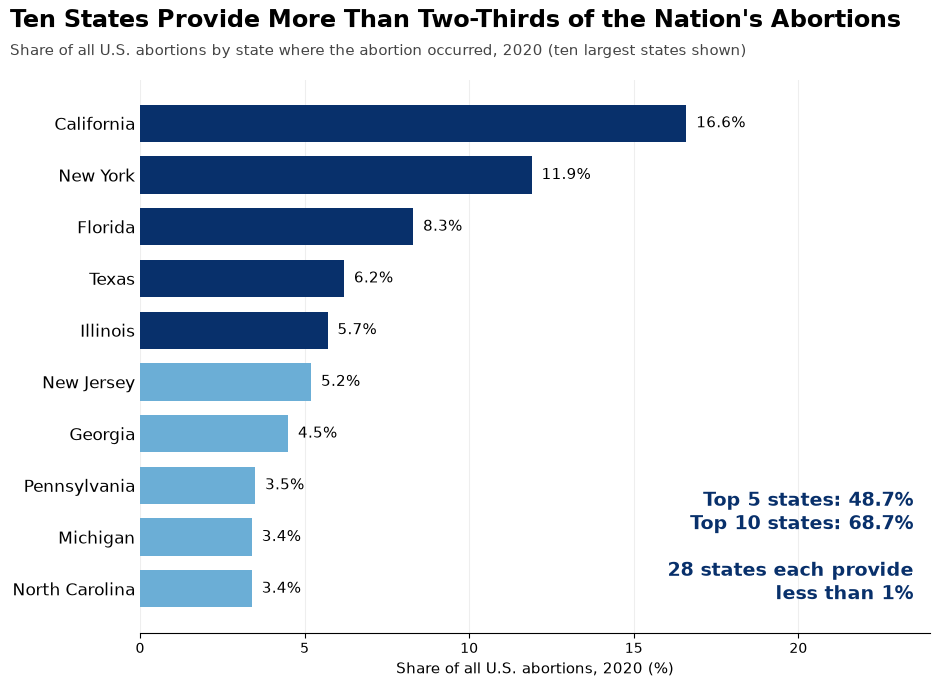

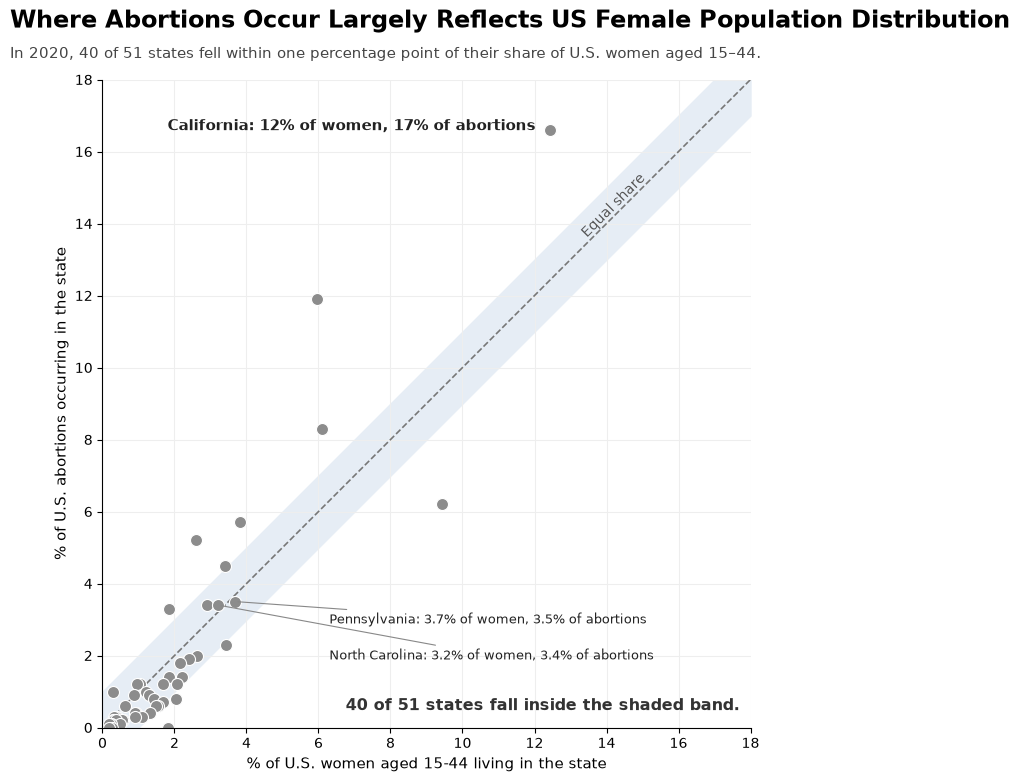

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

FILE = "GuttmacherInstituteAbortionDataByState.xlsx"
SHARE = "% of all U.S. abortions, by state of occurrence, 2020"
N_RES = "No. of abortions, by state of residence, 2020"
RATE = "No. of abortions per 1,000 women aged 15–44, by state of residence, 2020"

df = pd.read_excel(FILE, sheet_name="Guttmacher").rename(columns={"U.S. State": "state"})
for c in (SHARE, N_RES, RATE):
    df[c] = pd.to_numeric(df[c])

# The sheet has no population column: women 15-44 = abortions / (abortions per 1,000) * 1000
df["women_share"] = (df[N_RES] / df[RATE]) / (df[N_RES] / df[RATE]).sum() * 100
df = df.sort_values(SHARE, ascending=False).reset_index(drop=True)

top5, top10 = df[SHARE].head(5).sum(), df[SHARE].head(10).sum()
n_small = int((df[SHARE] < 1).sum())
BAND = 1.0
n_in = int(((df[SHARE] - df["women_share"]).abs() <= BAND).sum())
# Fail fast: these must match the figures quoted on the charts
assert round(top5, 1) == 48.7 and round(top10, 1) == 68.7 and n_small == 28, (top5, top10, n_small)
assert n_in == 40, n_in

# ---------- SUPPORT: a handful of states ----------
t = df.head(10)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(t["state"], t[SHARE], color=["#08306b"] * 5 + ["#6baed6"] * 5, height=0.72)
for i, v in enumerate(t[SHARE]):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=11)
ax.invert_yaxis()
ax.set_xlim(0, 24)
ax.set_xlabel("Share of all U.S. abortions, 2020 (%)", fontsize=11)
ax.xaxis.grid(True, color="#eeeeee"); ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=12)
ax.text(23.5, 8.2, f"Top 5 states: {top5:.1f}%\nTop 10 states: {top10:.1f}%\n\n{n_small} states each provide\nless than 1%",
        ha="right", va="center", fontsize=14, fontweight="bold", color="#08306b")
fig.text(0.04, 0.955, "Ten States Provide More Than Two-Thirds of the Nation's Abortions",
         fontsize=17, fontweight="bold", ha="left")
fig.text(0.04, 0.915, "Share of all U.S. abortions by state where the abortion occurred, 2020 (ten largest states shown)",
         fontsize=11, color="#444444", ha="left")
plt.subplots_adjust(top=0.88, bottom=0.09, left=0.17, right=0.96)
plt.savefig("fig_support2.png", dpi=200)
plt.show()

# ---------- OPPOSE: abortions are concentrated where the women are ----------
fig, ax = plt.subplots(figsize=(8.5, 8))
ax.fill_between([0, 18], [-BAND, 18 - BAND], [BAND, 18 + BAND], color="#e6edf5", zorder=0)
ax.plot([0, 18], [0, 18], color="#777777", linestyle="--", linewidth=1.2, zorder=1)
ax.text(14.2, 14.5, "Equal share", fontsize=10, color="#555555", rotation=45, rotation_mode="anchor", ha="center", va="center")
ax.scatter(df["women_share"], df[SHARE], s=75, color="#8c8c8c", edgecolor="white", linewidth=0.8, zorder=2)

ca = df[df["state"] == "California"].iloc[0]
ax.text(ca["women_share"] - 0.4, ca[SHARE] + 0.1, "California: 12% of women, 17% of abortions",
        fontsize=10.5, fontweight="bold", ha="right", va="center", color="#222222")
for name, (tx, ty) in {"Pennsylvania": (6.3, 3.0), "North Carolina": (6.3, 2.0)}.items():
    row = df[df["state"] == name].iloc[0]
    ax.annotate(f"{name}: {row['women_share']:.1f}% of women, {row[SHARE]:.1f}% of abortions",
                xy=(row["women_share"], row[SHARE]), xytext=(tx, ty), fontsize=9.5, va="center", color="#222222",
                arrowprops=dict(arrowstyle="-", color="#888888", linewidth=0.8))

ax.text(17.7, 0.6, f"{n_in} of {len(df)} states fall inside the shaded band.", ha="right", va="center",
        fontsize=11.5, fontweight="bold", color="#333333")
ax.set_xlim(0, 18); ax.set_ylim(0, 18); ax.set_aspect("equal")
ax.set_xlabel("% of U.S. women aged 15-44 living in the state", fontsize=11)
ax.set_ylabel("% of U.S. abortions occurring in the state", fontsize=11)
ax.grid(True, color="#eeeeee"); ax.set_axisbelow(True)
for s_ in ("top", "right"):
    ax.spines[s_].set_visible(False)
fig.text(0.04, 0.955, "Where Abortions Occur Largely Reflects US Female Population Distribution", fontsize=17, fontweight="bold", ha="left")
fig.text(0.04, 0.917, "In 2020, 40 of 51 states fell within one percentage point of their share of U.S. women aged 15–44.",
         fontsize=10.5, color="#444444", ha="left")
plt.subplots_adjust(top=0.89, bottom=0.08, left=0.10, right=0.96)
plt.savefig("fig_oppose3.png", dpi=200)
plt.show()